# Backhand, MediaPipe only (60 fps)
Clip `data/TableTennis1/vids/reves60.mp4` (front view, 5 backhand strokes). Keypoints from `scripts/pose_video.py --model mediapipe` (VIDEO mode, 33 landmarks). Same analysis settings as notebook 03 (SG 9 frames, same stroke detector), so numbers compare with its tables.
Figures: 1) right-wrist speed with the detected strokes, 2) wrist paths on the frame, 3) ankles over time. Each is also saved to `data/derived/TableTennis1/vids/reves60_mp_<name>.png`.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pose_tracker.stills import ROOT, COCO, MP_TO_COCO, torso_px
from pose_tracker.video import frame_times, read_keypoints
from pose_tracker.strokes import WR, speed, detect_strokes

CLIP = "reves60"
VID = ROOT / f"data/TableTennis1/vids/{CLIP}.mp4"
DER = ROOT / "data/derived/TableTennis1/vids"
t, xy33, vis33, names = read_keypoints(DER / f"{CLIP}_keypoints_mediapipe.csv")
assert np.allclose(t, frame_times(VID))
xy, vis = xy33[:, MP_TO_COCO], vis33[:, MP_TO_COCO]   # COCO-17 order for the shared stroke code
torso = float(np.nanmedian([torso_px(f) for f in xy]))
v = speed(xy[:, WR], t, 9) / torso
pk, half = detect_strokes(v, t)
print(f"{len(t)} frames, {t[-1]:.2f} s, frames without a person: {int(np.isnan(xy[:, 0, 0]).sum())}, torso {torso:.0f} px")
print(f"{len(pk)} strokes at t = {np.round(t[pk], 2)} s, peak speed {np.round(v[pk], 1)} torso/s "
      f"(mean {v[pk].mean():.1f} +- {v[pk].std():.1f}), window +-{half} frames ({half / 60:.2f} s)")

def frame(i):
    cap = cv2.VideoCapture(str(VID)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); _, fr = cap.read(); cap.release()
    return cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)

372 frames, 6.21 s, frames without a person: 0, torso 428 px
5 strokes at t = [1.04 2.11 3.18 4.38 5.69] s, peak speed [8.  7.4 7.5 8.2 8.3] torso/s (mean 7.9 +- 0.4), window +-34 frames (0.57 s)


## 1. Right-wrist speed
Speed of the paddle-hand wrist in torso lengths per second (Savitzky-Golay derivative, 9 frames = 150 ms). Crosses: detected strokes. At 60 fps the peak is a lower bound (notebook 04: 79-86 % of the 480 fps value).

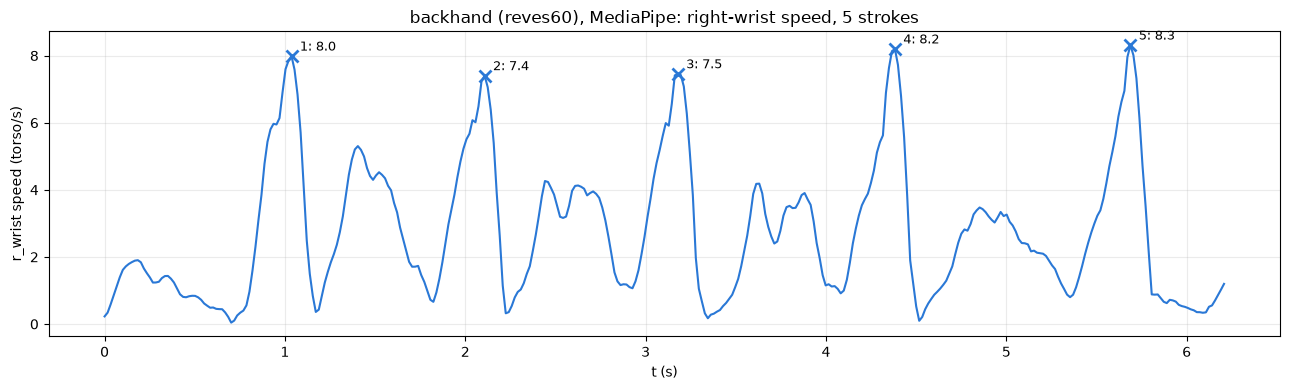

In [2]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t, v, color="#2a78d6", lw=1.5)
ax.plot(t[pk], v[pk], "x", color="#2a78d6", ms=9, mew=2)
for n, p in enumerate(pk, 1):
    ax.annotate(f"{n}: {v[p]:.1f}", (t[p], v[p]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("t (s)"); ax.set_ylabel("r_wrist speed (torso/s)"); ax.grid(alpha=0.25)
ax.set_title(f"backhand ({CLIP}), MediaPipe: right-wrist speed, {len(pk)} strokes")
fig.tight_layout(); fig.savefig(DER / f"{CLIP}_mp_wrist_speed.png", dpi=110); plt.show()

## 2. Wrist paths
Right-wrist position in each stroke window (peak +- half the median stroke period), coloured by time within the window (dark = start, yellow = end). Red x: position at peak speed. Background: frame at the first peak.

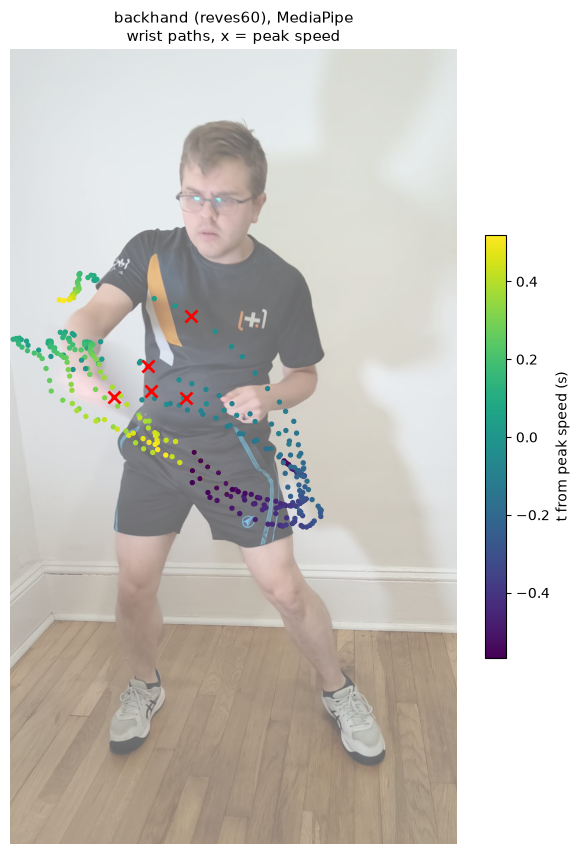

In [3]:
fig, ax = plt.subplots(figsize=(6, 9))
ax.imshow(frame(pk[0]), alpha=0.6)
for p in pk:
    lo, hi = max(0, p - half), min(len(t), p + half + 1)
    sc = ax.scatter(*xy[lo:hi, WR].T, c=t[lo:hi] - t[p], cmap="viridis", s=8)
    ax.plot(*xy[p, WR], "rx", ms=9, mew=2)
fig.colorbar(sc, ax=ax, shrink=0.5, label="t from peak speed (s)")
ax.set_title(f"backhand ({CLIP}), MediaPipe\nwrist paths, x = peak speed", fontsize=11); ax.axis("off")
fig.tight_layout(); fig.savefig(DER / f"{CLIP}_mp_wrist_paths.png", dpi=110); plt.show()

## 3. Ankles
l_ankle (blue) and r_ankle (orange) over time, image pixels; y inverted so up is up in the image. Bottom: MediaPipe visibility. Gray lines: stroke peaks.

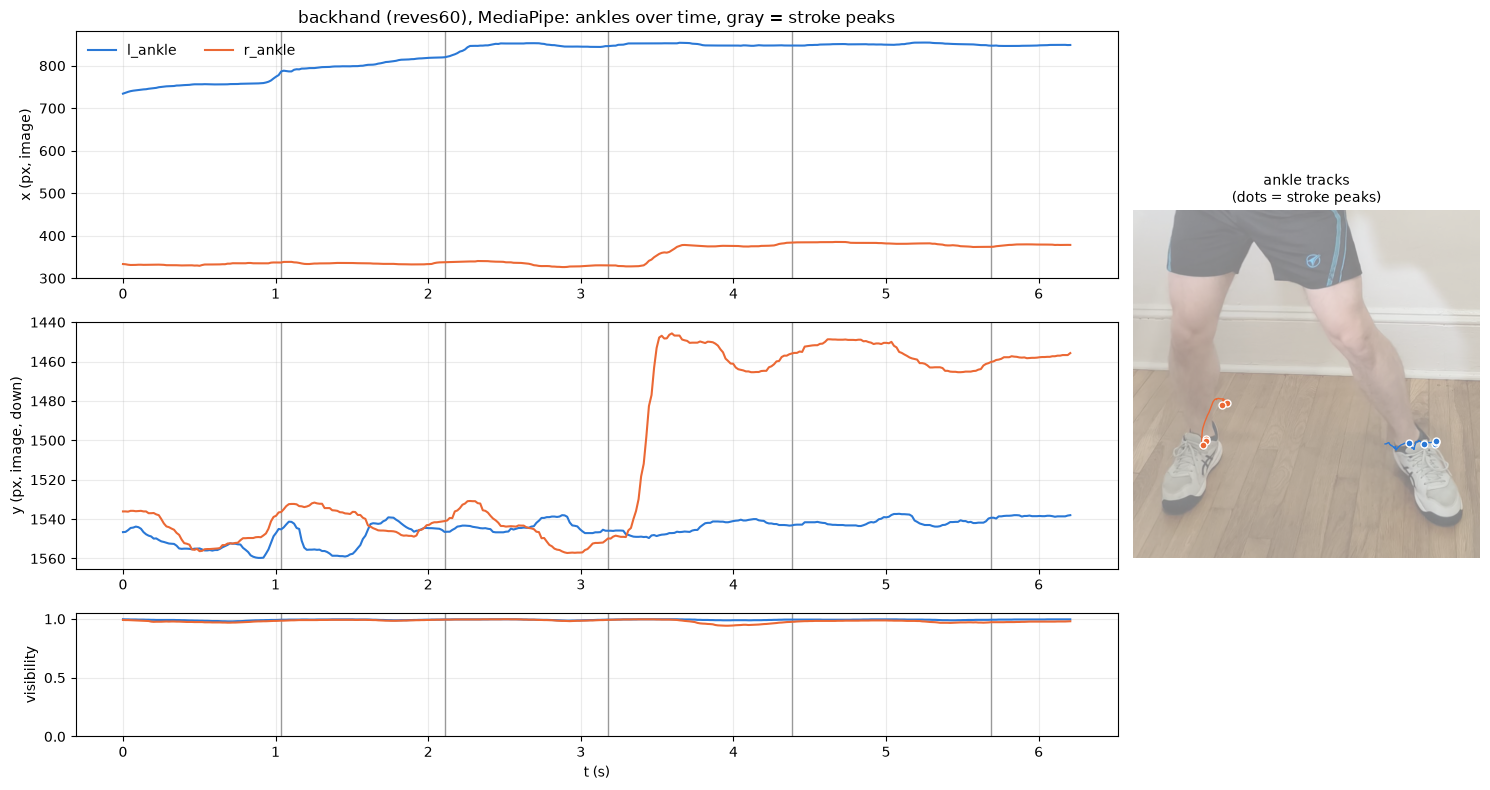

l_ankle: net shift start -> end x +114 px, y -9 px (0.27 torso); median visibility 0.99
r_ankle: net shift start -> end x +45 px, y -80 px (0.22 torso); median visibility 0.98


In [4]:
LA, RA = COCO.index("l_ankle"), COCO.index("r_ankle")
ACOL = {LA: "#2a78d6", RA: "#eb6834"}
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(3, 2, width_ratios=[3, 1], height_ratios=[2, 2, 1])
ax = [fig.add_subplot(gs[0, 0])]
ax += [fig.add_subplot(gs[i, 0], sharex=ax[0]) for i in (1, 2)]
for j in (LA, RA):
    ax[0].plot(t, xy[:, j, 0], color=ACOL[j], lw=1.5, label=COCO[j])
    ax[1].plot(t, xy[:, j, 1], color=ACOL[j], lw=1.5)
    ax[2].plot(t, vis[:, j], color=ACOL[j], lw=1.5)
for a in ax:
    for p in pk:
        a.axvline(t[p], color="0.6", lw=1, zorder=0)
    a.grid(alpha=0.25)
ax[0].set_ylabel("x (px, image)"); ax[0].legend(ncol=2, loc="upper left", frameon=False)
ax[1].set_ylabel("y (px, image, down)"); ax[1].invert_yaxis()
ax[2].set_ylabel("visibility"); ax[2].set_ylim(0, 1.05); ax[2].set_xlabel("t (s)")
ax[0].set_title(f"backhand ({CLIP}), MediaPipe: ankles over time, gray = stroke peaks")

im = fig.add_subplot(gs[:, 1]); fr = frame(pk[0])
im.imshow(fr, alpha=0.5)
for j in (LA, RA):
    im.plot(*xy[:, j].T, color=ACOL[j], lw=1)
    im.plot(*xy[pk, j].T, "o", color=ACOL[j], ms=5, mec="white")
pts = xy[:, [LA, RA]].reshape(-1, 2); cx, cy = np.nanmedian(pts, axis=0); h = 0.6 * torso
x0 = min(max(cx - 1.5 * h, 0), fr.shape[1] - 3 * h)
im.set_xlim(x0, x0 + 3 * h); im.set_ylim(cy + h, cy - 2 * h)
im.set_title("ankle tracks\n(dots = stroke peaks)", fontsize=10); im.axis("off")
fig.tight_layout(); fig.savefig(DER / f"{CLIP}_mp_ankles.png", dpi=110); plt.show()

for j in (LA, RA):
    d = xy[:, j] - xy[0, j]
    print(f"{COCO[j]}: net shift start -> end x {d[-1, 0]:+.0f} px, y {d[-1, 1]:+.0f} px "
          f"({np.linalg.norm(d[-1]) / torso:.2f} torso); median visibility {np.nanmedian(vis[:, j]):.2f}")